# 05 · Experiments (Phase 8): answering the research question

> **RQ:** When an SER model trained on one acted English corpus is applied to another, do its accuracy and its SHAP explanations hold up, and can explanation stability be used to choose features that transfer better?

| Exp. | Question | Hypothesis |
|---|---|---|
| **E2** | How much accuracy is lost across corpora, for eGeMAPS vs WavLM? | **H1:** WavLM wins in-corpus but loses *relatively more* across corpora |
| **E3** | How stable are SHAP rankings across resamples, speakers and corpora? | **H2:** stability falls resample > speaker > corpus, yet stays above a random baseline |
| **E4** | Do consistently-important ("stable-core") features transfer better than top-importance features? | **H3:** stable core loses less accuracy cross-corpus |
| **E5** | Where do errors come from? (classes, gender, age, label agreement) | — |

Leak-free: layer, hyperparameters and feature subsets are chosen on the **source** corpus only.
Uncertainty: **speaker-level bootstrap** (target speakers resampled, 1,000×) → 95% CI.
Results are cached in `results/phase8/` (set `REDO=True` to recompute). ⏱ First run ≈ 45–75 min.

In [1]:
import sys, json, time, itertools
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, spearmanr
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, recall_score
from src.models import load_corpus, features, CLASSES, DEFAULT_LAYER
from src.explain import feature_group, GROUPS
from src.experiments import (cross_corpus, speaker_bootstrap, ci, corpus_standardise, FIXED_C,
                             importance_logreg, importance_lgbm, speaker_subsets, similarity,
                             null_similarity, subset_importances, stability_scores, select_stable,
                             select_top_importance, transfer_with_subset)

REDO = False
OUT = PROJECT_ROOT / "results" / "phase8"; OUT.mkdir(parents=True, exist_ok=True)
P6 = PROJECT_ROOT / "results" / "phase6"
FIG_DIR = PROJECT_ROOT / "results" / "figures"
NAME = {"ravdess": "RAVDESS", "cremad": "CREMA-D"}
DIRS = [("ravdess", "cremad"), ("cremad", "ravdess")]
FS = ["egemaps", "wavlm", "fusion"]; MODELS = ["logreg", "svm", "lgbm", "mlp"]
BLUE, ORANGE, AQUA, YELLOW, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#0b0b0b", "#52514e"
GREY = "#b8b6ad"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.edgecolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "figure.dpi": 110})
data = {c: load_corpus(c) for c in ["ravdess", "cremad"]}
NAMES = data["ravdess"]["egemaps_names"]
summary = {}

## E2 · Cross-corpus transfer (H1)
Two normalisation variants:
- **source**: scaler fitted on the training corpus only (strictest).
- **corpus**: each corpus standardised with its own mean/std first. This uses the target's **unlabelled** feature statistics, a simple, common unsupervised adaptation.

*In-domain* = the target corpus's own speaker-independent score from Phase 6 (same features, same model): the "ceiling" for that corpus.

In [2]:
from src.models import select_layer
layer_src = {}
for s in ["ravdess", "cremad"]:          # WavLM layer chosen once per SOURCE corpus (training data only)
    f = OUT / f"e2_layer_{s}.json"
    if f.exists() and not REDO:
        layer_src[s] = json.loads(f.read_text())["layer"]
    else:
        layer_src[s] = select_layer(data[s]["wavlm"], data[s]["y"], data[s]["groups"])[0]
        f.write_text(json.dumps({"layer": layer_src[s]}))
print("WavLM layer chosen on each source corpus:", layer_src)

rows = []
for (s, t), fs, m, norm in itertools.product(DIRS, FS, MODELS, ["source", "corpus"]):
    tag = f"{s}_to_{t}_{fs}_{m}_{norm}"
    f = OUT / f"e2_{tag}.npy"
    if f.exists() and not REDO:
        pred = np.load(f); meta = json.loads((OUT / f"e2_{tag}.json").read_text())
    else:
        t0 = time.time()
        r = cross_corpus(data[s], data[t], fs, m, norm=norm, layer=layer_src[s])
        pred = r["pred"]; np.save(f, pred)
        meta = {"layer": r["layer"], "params": str(r["params"])}
        (OUT / f"e2_{tag}.json").write_text(json.dumps(meta))
        print(f"{tag:42s} UAR {balanced_accuracy_score(data[t]['y'], pred):.3f}  ({time.time()-t0:.0f}s)")
    indomain = np.load(P6 / f"e1_{t}_{fs}_{m}_oof.npy")
    rows.append({"source": s, "target": t, "features": fs, "model": m, "norm": norm,
                 "cross_uar": balanced_accuracy_score(data[t]["y"], pred),
                 "indomain_uar": balanced_accuracy_score(data[t]["y"], indomain), **meta})
e2 = pd.DataFrame(rows)
e2["drop_pts"] = 100 * (e2["indomain_uar"] - e2["cross_uar"])
e2["relative_drop"] = 1 - e2["cross_uar"] / e2["indomain_uar"]
e2.to_csv(OUT / "e2_all.csv", index=False)
for (s, t) in DIRS:
    print(f"\n{NAME[s]} -> {NAME[t]}: cross-corpus UAR % (in-domain on {NAME[t]} in brackets)")
    sub = e2[(e2.source == s)]
    for norm in ["source", "corpus"]:
        tab = sub[sub.norm == norm].pivot(index="model", columns="features", values="cross_uar")[FS] * 100
        ind = sub[sub.norm == norm].pivot(index="model", columns="features", values="indomain_uar")[FS] * 100
        print(f"  normalisation = {norm}")
        print((tab.round(1).astype(str) + " (" + ind.round(1).astype(str) + ")").to_string())

WavLM layer chosen on each source corpus: {'ravdess': 6, 'cremad': 7}
ravdess_to_cremad_egemaps_logreg_source    UAR 0.301  (0s)
ravdess_to_cremad_egemaps_logreg_corpus    UAR 0.356  (0s)
ravdess_to_cremad_egemaps_svm_source       UAR 0.318  (0s)
ravdess_to_cremad_egemaps_svm_corpus       UAR 0.354  (0s)
ravdess_to_cremad_egemaps_lgbm_source      UAR 0.347  (3s)
ravdess_to_cremad_egemaps_lgbm_corpus      UAR 0.329  (3s)
ravdess_to_cremad_egemaps_mlp_source       UAR 0.291  (0s)
ravdess_to_cremad_egemaps_mlp_corpus       UAR 0.338  (0s)
ravdess_to_cremad_wavlm_logreg_source      UAR 0.387  (0s)
ravdess_to_cremad_wavlm_logreg_corpus      UAR 0.450  (0s)
ravdess_to_cremad_wavlm_svm_source         UAR 0.206  (2s)
ravdess_to_cremad_wavlm_svm_corpus         UAR 0.432  (2s)
ravdess_to_cremad_wavlm_lgbm_source        UAR 0.346  (22s)
ravdess_to_cremad_wavlm_lgbm_corpus        UAR 0.378  (22s)
ravdess_to_cremad_wavlm_mlp_source         UAR 0.336  (0s)
ravdess_to_cremad_wavlm_mlp_corpus         

### H1 test: is WavLM's relative drop larger than eGeMAPS's? (LogReg, paired speaker bootstrap)
Relative drop = 1 − cross / in-domain. Both are computed on the **same resampled target speakers**, so the comparison is paired.

In [3]:
h1 = []
for (s, t), norm in itertools.product(DIRS, ["source", "corpus"]):
    y, g = data[t]["y"], data[t]["groups"]
    preds = {}
    for fs in ["egemaps", "wavlm", "fusion"]:
        preds[f"cross_{fs}"] = np.load(OUT / f"e2_{s}_to_{t}_{fs}_logreg_{norm}.npy")
        preds[f"in_{fs}"] = np.load(P6 / f"e1_{t}_{fs}_logreg_oof.npy")
    B = speaker_bootstrap(y, preds, g, n_boot=1000)
    rd = {fs: 1 - B[f"cross_{fs}"] / B[f"in_{fs}"] for fs in ["egemaps", "wavlm", "fusion"]}
    diff = rd["wavlm"] - rd["egemaps"]
    row = {"direction": f"{NAME[s]}→{NAME[t]}", "norm": norm}
    for fs in ["egemaps", "wavlm", "fusion"]:
        row[f"{fs}_cross_uar"] = f"{100*balanced_accuracy_score(y, preds['cross_'+fs]):.1f} [{100*ci(B['cross_'+fs])[0]:.1f}, {100*ci(B['cross_'+fs])[1]:.1f}]"
        row[f"{fs}_rel_drop"] = f"{100*np.mean(rd[fs]):.1f}%"
    lo, hi = ci(diff)
    row["wavlm_minus_egemaps_rel_drop"] = f"{100*np.mean(diff):+.1f} pts [{100*lo:+.1f}, {100*hi:+.1f}]"
    row["H1_supported"] = bool(lo > 0)
    h1.append(row)
h1 = pd.DataFrame(h1); h1.to_csv(OUT / "e2_h1_test.csv", index=False)
summary["E2_H1"] = h1.to_dict(orient="records")
h1

,direction,norm,egemaps_cross_uar,egemaps_rel_drop,wavlm_cross_uar,wavlm_rel_drop,fusion_cross_uar,fusion_rel_drop,wavlm_minus_egemaps_rel_drop,H1_supported
0,RAVDESS→CREMA-D,source,"30.1 [28.9, 31.2]",41.4%,"38.7 [37.0, 40.6]",47.5%,"42.1 [40.2, 44.0]",43.1%,"+6.1 pts [+3.1, +9.4]",True
1,RAVDESS→CREMA-D,corpus,"35.6 [34.3, 36.9]",30.7%,"45.0 [43.3, 46.7]",39.0%,"48.6 [46.8, 50.6]",34.3%,"+8.3 pts [+5.1, +11.6]",True
2,CREMA-D→RAVDESS,source,"30.0 [27.0, 33.2]",45.7%,"58.8 [54.7, 62.9]",27.3%,"66.3 [62.8, 70.1]",19.1%,"-18.4 pts [-27.9, -8.1]",False
3,CREMA-D→RAVDESS,corpus,"43.2 [41.2, 45.3]",21.9%,"67.8 [65.1, 70.5]",16.2%,"68.3 [65.6, 70.9]",16.7%,"-5.7 pts [-12.4, +1.4]",False


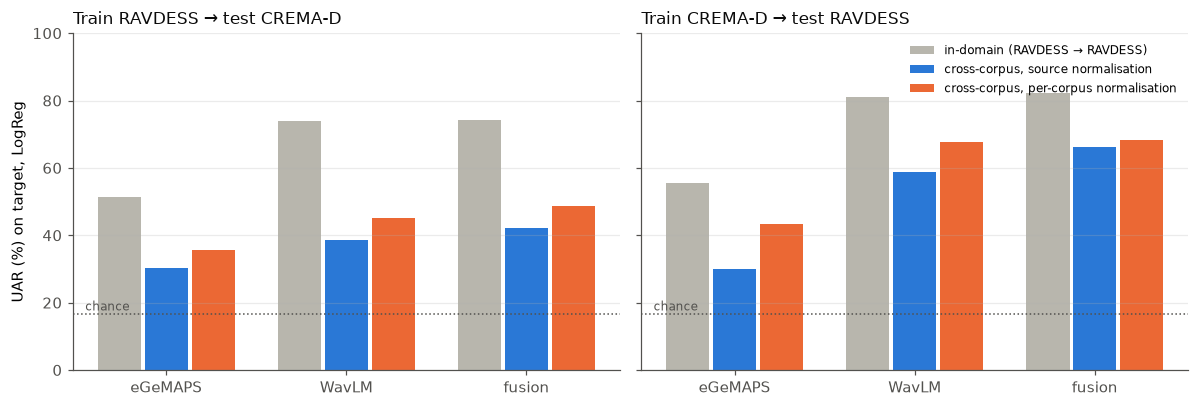

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (s, t) in zip(axes, DIRS):
    sub = e2[(e2.source == s) & (e2.model == "logreg")]
    x = np.arange(len(FS)); w = 0.26
    ind = sub[sub.norm == "source"].set_index("features").loc[FS, "indomain_uar"] * 100
    cs = sub[sub.norm == "source"].set_index("features").loc[FS, "cross_uar"] * 100
    cc = sub[sub.norm == "corpus"].set_index("features").loc[FS, "cross_uar"] * 100
    ax.bar(x - w, ind, w * 0.92, color=GREY, label=f"in-domain ({NAME[t]} → {NAME[t]})")
    ax.bar(x, cs, w * 0.92, color=BLUE, label="cross-corpus, source normalisation")
    ax.bar(x + w, cc, w * 0.92, color=ORANGE, label="cross-corpus, per-corpus normalisation")
    ax.axhline(100 / 6, color=MUTED, ls=":", lw=1); ax.text(-0.45, 100 / 6 + 1, "chance", color=MUTED, fontsize=8)
    ax.set_xticks(x, ["eGeMAPS", "WavLM", "fusion"]); ax.set_ylim(0, 100); ax.grid(axis="x", visible=False)
    ax.set_title(f"Train {NAME[s]} → test {NAME[t]}", loc="left", color=INK, fontsize=11)
axes[0].set_ylabel("UAR (%) on target, LogReg"); axes[1].legend(frameon=False, fontsize=8, loc="upper right")
fig.tight_layout(); fig.savefig(FIG_DIR / "p8_e2_cross_corpus.png", bbox_inches="tight"); plt.show()

## E3 · Explanation stability (H2)
All models are trained on **12 speakers** (RAVDESS has 24, so two disjoint halves are possible), so the comparison between corpora is fair in size.
Importance = mean |SHAP| on the model's own training clips. Three levels of change:

| Level | What differs between the two models compared |
|---|---|
| **resample** | same 12 speakers, bootstrap-resampled clips |
| **speaker** | two *disjoint* sets of 12 speakers, same corpus |
| **corpus** | 12 RAVDESS speakers vs 12 CREMA-D speakers |

Representations: LogReg + eGeMAPS (88, top-10), LightGBM + eGeMAPS (88, top-10), LogReg + WavLM layer 6 (768, top-77 = 10%).
Baseline: similarity between **random** rankings.

In [5]:
R = 10; NSPK = 12
REPS = {"LogReg·eGeMAPS": ("egemaps", "logreg", 10), "LightGBM·eGeMAPS": ("egemaps", "lgbm", 10),
        "LogReg·WavLM-L6": ("wavlm", "logreg", 77)}

def imp_fn(fs, m, X, y):
    return importance_logreg(X, y, FIXED_C[fs]) if m == "logreg" else importance_lgbm(X, y)

f_e3 = OUT / "e3_pairs.csv"
if f_e3.exists() and not REDO:
    e3 = pd.read_csv(f_e3)
else:
    rows = []; t0 = time.time()
    for rep, (fs, m, k) in REPS.items():
        speaker_models = {}
        for c in ["ravdess", "cremad"]:
            d = data[c]; X = features(d, fs, DEFAULT_LAYER); y, g = d["y"], d["groups"]
            pairs = list(speaker_subsets(g, NSPK, R, seed=1))
            # speaker level: disjoint halves
            models_c = []
            for a, b in pairs:
                ia = imp_fn(fs, m, X[np.isin(g, list(a))], y[np.isin(g, list(a))])
                ib = imp_fn(fs, m, X[np.isin(g, list(b))], y[np.isin(g, list(b))])
                rows.append({"rep": rep, "level": "speaker", "corpus": NAME[c], **similarity(ia, ib, k)})
                models_c += [ia, ib]
            speaker_models[c] = models_c
            # resample level: same 12 speakers, bootstrap clips
            base = np.where(np.isin(g, list(pairs[0][0])))[0]
            rng = np.random.default_rng(2)
            boots = [imp_fn(fs, m, X[idx], y[idx]) for idx in (rng.choice(base, len(base), replace=True) for _ in range(R))]
            for i, j in itertools.combinations(range(R), 2):
                rows.append({"rep": rep, "level": "resample", "corpus": NAME[c], **similarity(boots[i], boots[j], k)})
        # corpus level: every RAVDESS model vs every CREMA-D model
        for ia in speaker_models["ravdess"]:
            for ib in speaker_models["cremad"]:
                rows.append({"rep": rep, "level": "corpus", "corpus": "both", **similarity(ia, ib, k)})
        print(f"{rep} done ({time.time()-t0:.0f}s)")
    e3 = pd.DataFrame(rows); e3.to_csv(f_e3, index=False)

null = {rep: null_similarity(88 if fs == "egemaps" else 768, k) for rep, (fs, m, k) in REPS.items()}
LEVELS = ["resample", "speaker", "corpus"]
tab = e3.groupby(["rep", "level"])[["spearman", "topk_jaccard"]].median().unstack("level")
for rep in REPS:
    tab.loc[rep, ("spearman", "random")] = null[rep]["spearman"].median()
    tab.loc[rep, ("topk_jaccard", "random")] = null[rep]["topk_jaccard"].median()
print("Median similarity between importance rankings")
print(tab.round(3).to_string())

LogReg·eGeMAPS done (1s)
LightGBM·eGeMAPS done (90s)
LogReg·WavLM-L6 done (93s)
Median similarity between importance rankings
                 spearman                  topk_jaccard                  spearman topk_jaccard
level              corpus resample speaker       corpus resample speaker   random       random
rep                                                                                           
LightGBM·eGeMAPS    0.197    0.760   0.441        0.111    0.538   0.250    0.004        0.053
LogReg·WavLM-L6     0.104    0.677   0.337        0.085    0.333   0.158    0.001        0.055
LogReg·eGeMAPS      0.495    0.780   0.631        0.176    0.429   0.250    0.004        0.053


In [6]:
h2 = []
for rep in REPS:
    sub = e3[e3.rep == rep]
    r, s_, c_ = (sub[sub.level == L]["spearman"] for L in LEVELS)
    p_rs = mannwhitneyu(r, s_, alternative="greater").pvalue
    p_sc = mannwhitneyu(s_, c_, alternative="greater").pvalue
    p_cn = mannwhitneyu(c_, null[rep]["spearman"], alternative="greater").pvalue
    h2.append({"representation": rep, "median_resample": round(r.median(), 3), "median_speaker": round(s_.median(), 3),
               "median_corpus": round(c_.median(), 3), "median_random": round(null[rep]["spearman"].median(), 3),
               "p_resample>speaker": p_rs, "p_speaker>corpus": p_sc, "p_corpus>random": p_cn,
               "H2_order_holds": bool(p_rs < 0.05 and p_sc < 0.05 and p_cn < 0.05)})
h2 = pd.DataFrame(h2); h2.to_csv(OUT / "e3_h2_test.csv", index=False)
summary["E3_H2"] = h2.to_dict(orient="records")
print("Note: pairs share models, so p-values are approximate (pairs are not fully independent).")
h2

Note: pairs share models, so p-values are approximate (pairs are not fully independent).


,representation,median_resample,median_speaker,median_corpus,median_random,p_resample>speaker,p_speaker>corpus,p_corpus>random,H2_order_holds
0,LogReg·eGeMAPS,0.780,0.631,0.495,0.004,7.134422e-11,5.884951e-12,1.385470e-188,True
1,LightGBM·eGeMAPS,0.760,0.441,0.197,0.004,1.573666e-12,5.979605e-14,1.799450e-137,True
2,LogReg·WavLM-L6,0.677,0.337,0.104,0.001,1.573666e-12,2.186969e-14,7.641132e-178,True


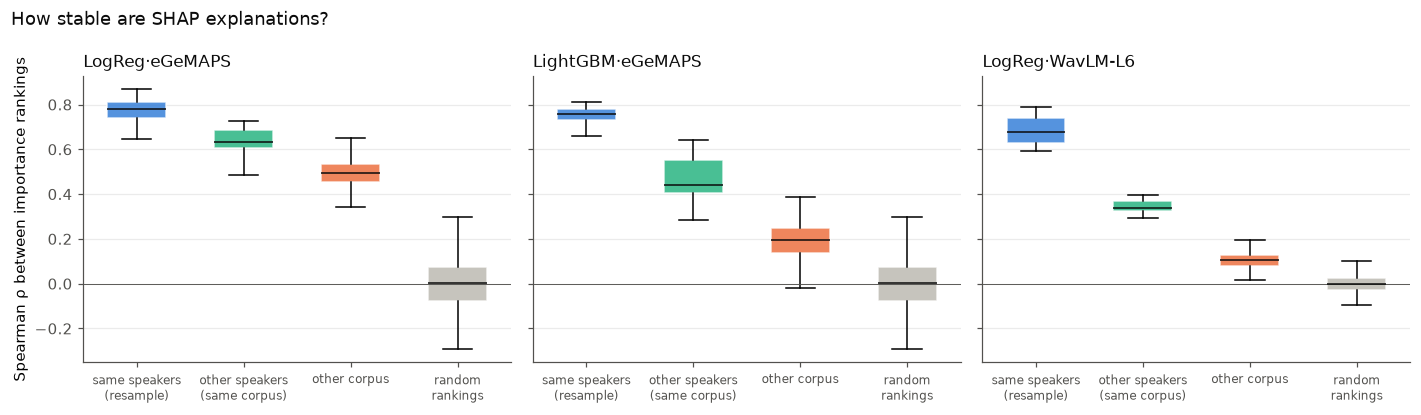

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
cols = {"resample": BLUE, "speaker": AQUA, "corpus": ORANGE}
for ax, rep in zip(axes, REPS):
    sub = e3[e3.rep == rep]
    vals = [sub[sub.level == L]["spearman"].values for L in LEVELS] + [null[rep]["spearman"].values]
    bp = ax.boxplot(vals, widths=0.55, patch_artist=True, showfliers=False, medianprops={"color": INK})
    for patch, col in zip(bp["boxes"], [cols[L] for L in LEVELS] + [GREY]):
        patch.set_facecolor(col); patch.set_alpha(0.8); patch.set_edgecolor("white")
    ax.set_xticks(range(1, 5), ["same speakers\n(resample)", "other speakers\n(same corpus)", "other corpus", "random\nrankings"], fontsize=8)
    ax.axhline(0, color=MUTED, lw=0.6); ax.grid(axis="x", visible=False)
    ax.set_title(rep, loc="left", color=INK, fontsize=11)
axes[0].set_ylabel("Spearman ρ between importance rankings")
fig.suptitle("How stable are SHAP explanations?", x=0.01, ha="left", color=INK)
fig.tight_layout(); fig.savefig(FIG_DIR / "p8_e3_stability.png", bbox_inches="tight"); plt.show()

### Are *groups* (Energy / Frequency / Spectral / Temporal) more stable than single features?

In [8]:
grp = np.array([feature_group(n) for n in NAMES])
rows = []
for c in ["ravdess", "cremad"]:
    d = data[c]; X, y, g = d["egemaps"], d["y"], d["groups"]
    for a, b in speaker_subsets(g, NSPK, R, seed=1):
        for sset in (a, b):
            m = np.isin(g, list(sset)); imp = importance_logreg(X[m], y[m], FIXED_C["egemaps"])
            sh = pd.Series(imp).groupby(grp).sum(); sh = sh / sh.sum()
            per = sh / pd.Series(grp).value_counts()
            rows.append({"corpus": NAME[c], **{f"{G} (per feature)": per[G] / per.sum() for G in GROUPS}})
gs = pd.DataFrame(rows)
gtab = gs.groupby("corpus").agg(["mean", "std"]).round(3)
summary["E3_group_shares"] = {c: {k[0]: [float(v) for v in gtab.loc[c, k[0]]] for k in gtab.columns[::2]} for c in gtab.index}
gtab

Energy (per feature)        Frequency (per feature)         \
                        mean    std                    mean    std   
corpus                                                               
CREMA-D                0.293  0.025                   0.210  0.018   
RAVDESS                0.269  0.019                   0.253  0.011   

        Spectral (per feature)        Temporal (per feature)         
                          mean    std                   mean    std  
corpus                                                               
CREMA-D                  0.220  0.013                  0.277  0.032  
RAVDESS                  0.217  0.012                  0.261  0.019

## E4 · Does a "stable core" of features transfer better? (H3)
On the **source** corpus only: 20 LogReg models are trained on random halves of the speakers. A feature's *stability* = how often it lands in the top-k.
- **stable core (k)**: the k most consistently top-ranked features
- **top importance (k)**: the k most important features of one model trained on all source data (the usual approach)
- **random (k)**: mean of 20 random k-subsets · **all 88**: no selection

In [9]:
f_e4 = OUT / "e4_results.csv"
KS = [10, 20, 30]
if f_e4.exists() and not REDO:
    e4 = pd.read_csv(f_e4)
else:
    rows = []
    for (s, t), norm in itertools.product(DIRS, ["source", "corpus"]):
        Xs, ys, gs_ = data[s]["egemaps"], data[s]["y"], data[s]["groups"]
        Xt, yt = data[t]["egemaps"], data[t]["y"]
        if norm == "corpus":
            Xs, Xt = corpus_standardise(Xs), corpus_standardise(Xt)
        C = FIXED_C["egemaps"]
        imps = subset_importances(Xs, ys, gs_, C, n_models=20, seed=3)
        all_pred = transfer_with_subset(Xs, ys, Xt, np.arange(88), C)
        rows.append({"direction": f"{NAME[s]}→{NAME[t]}", "norm": norm, "k": 88, "selection": "all",
                     "uar": balanced_accuracy_score(yt, all_pred), "overlap_with_top": np.nan})
        for k in KS:
            stable = select_stable(stability_scores(imps, k), k)
            top = select_top_importance(Xs, ys, C, k)
            for name, cols_ in [("stable core", stable), ("top importance", top)]:
                p = transfer_with_subset(Xs, ys, Xt, cols_, C)
                np.save(OUT / f"e4_{s}_{norm}_{k}_{name.replace(' ', '_')}.npy", p)
                rows.append({"direction": f"{NAME[s]}→{NAME[t]}", "norm": norm, "k": k, "selection": name,
                             "uar": balanced_accuracy_score(yt, p), "overlap_with_top": len(set(stable) & set(top)) / k,
                             "features": ";".join(NAMES[j] for j in cols_)})
            rng = np.random.default_rng(4)
            rand = [balanced_accuracy_score(yt, transfer_with_subset(Xs, ys, Xt, rng.choice(88, k, replace=False), C)) for _ in range(20)]
            rows.append({"direction": f"{NAME[s]}→{NAME[t]}", "norm": norm, "k": k, "selection": "random",
                         "uar": float(np.mean(rand)), "overlap_with_top": np.nan})
    e4 = pd.DataFrame(rows); e4.to_csv(f_e4, index=False)
print((e4.pivot_table(index=["direction", "norm", "k"], columns="selection", values="uar") * 100).round(1).to_string())
print("\nOverlap between stable core and top-importance sets:")
print(e4[e4.selection == "stable core"][["direction", "norm", "k", "overlap_with_top"]].to_string(index=False))

selection                   all  random  stable core  top importance
direction       norm   k                                            
CREMA-D→RAVDESS corpus 10   NaN    34.6         36.0            34.6
                       20   NaN    40.4         43.4            40.9
                       30   NaN    41.6         46.2            41.1
                       88  46.0     NaN          NaN             NaN
                source 10   NaN    27.9         25.7            29.5
                       20   NaN    30.4         31.9            30.5
                       30   NaN    29.8         30.2            31.2
                       88  29.8     NaN          NaN             NaN
RAVDESS→CREMA-D corpus 10   NaN    30.4         35.0            34.0
                       20   NaN    33.6         35.0            36.3
                       30   NaN    34.2         36.1            36.4
                       88  35.6     NaN          NaN             NaN
                source 10   NaN   

In [10]:
h3 = []
for (s, t), norm in itertools.product(DIRS, ["source", "corpus"]):
    yt, gt = data[t]["y"], data[t]["groups"]
    for k in KS:
        p_st = np.load(OUT / f"e4_{s}_{norm}_{k}_stable_core.npy")
        p_top = np.load(OUT / f"e4_{s}_{norm}_{k}_top_importance.npy")
        B = speaker_bootstrap(yt, {"st": p_st, "top": p_top}, gt, n_boot=1000)
        d = B["st"] - B["top"]; lo, hi = ci(d)
        h3.append({"direction": f"{NAME[s]}→{NAME[t]}", "norm": norm, "k": k,
                   "stable_minus_top_pts": round(100 * float(np.mean(d)), 2),
                   "ci95": f"[{100*lo:+.1f}, {100*hi:+.1f}]", "significant": bool(lo > 0 or hi < 0)})
h3 = pd.DataFrame(h3); h3.to_csv(OUT / "e4_h3_test.csv", index=False)
summary["E4_H3"] = h3.to_dict(orient="records")
h3

,direction,norm,k,stable_minus_top_pts,ci95,significant
0,RAVDESS→CREMA-D,source,10,-0.41,"[-1.7, +0.9]",False
1,RAVDESS→CREMA-D,source,20,-1.21,"[-1.9, -0.5]",True
2,RAVDESS→CREMA-D,source,30,-1.27,"[-2.0, -0.6]",True
3,RAVDESS→CREMA-D,corpus,10,0.95,"[-0.2, +2.1]",False
4,RAVDESS→CREMA-D,corpus,20,-1.32,"[-2.2, -0.5]",True
5,RAVDESS→CREMA-D,corpus,30,-0.30,"[-1.1, +0.6]",False
6,CREMA-D→RAVDESS,source,10,-3.78,"[-7.0, -0.7]",True
7,CREMA-D→RAVDESS,source,20,1.41,"[-1.1, +3.8]",False
8,CREMA-D→RAVDESS,source,30,-0.93,"[-3.9, +2.0]",False
9,CREMA-D→RAVDESS,corpus,10,1.46,"[-1.8, +4.9]",False


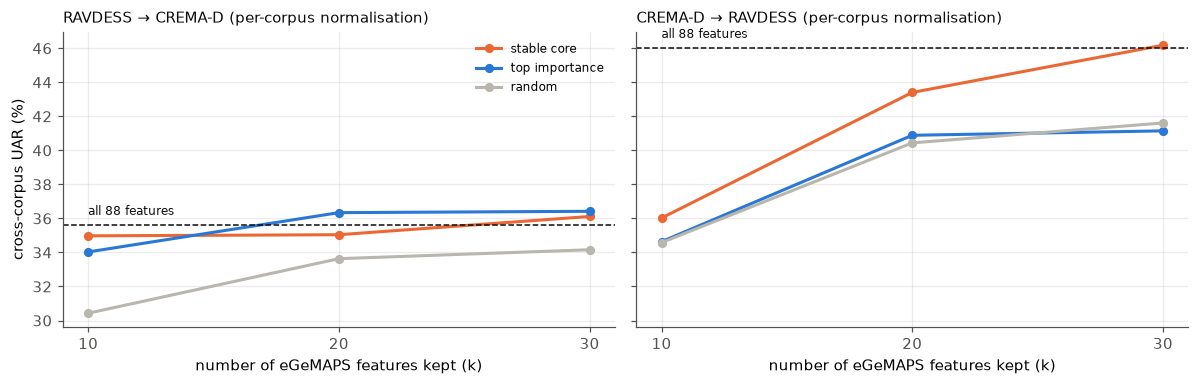

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
st = {"stable core": ORANGE, "top importance": BLUE, "random": GREY}
for ax, (s, t) in zip(axes, DIRS):
    sub = e4[(e4.direction == f"{NAME[s]}→{NAME[t]}") & (e4.norm == "corpus")]
    for sel, col in st.items():
        r = sub[sub.selection == sel].sort_values("k")
        ax.plot(r["k"], r["uar"] * 100, marker="o", ms=5, lw=2, color=col, label=sel)
    allu = sub[sub.selection == "all"]["uar"].iloc[0] * 100
    ax.axhline(allu, color=INK, ls="--", lw=1); ax.text(10, allu + 0.6, "all 88 features", fontsize=8, color=INK)
    ax.set_xticks(KS); ax.set_xlabel("number of eGeMAPS features kept (k)")
    ax.set_title(f"{NAME[s]} → {NAME[t]} (per-corpus normalisation)", loc="left", color=INK, fontsize=10)
axes[0].set_ylabel("cross-corpus UAR (%)"); axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "p8_e4_stable_core.png", bbox_inches="tight"); plt.show()

## E5 · Error analysis

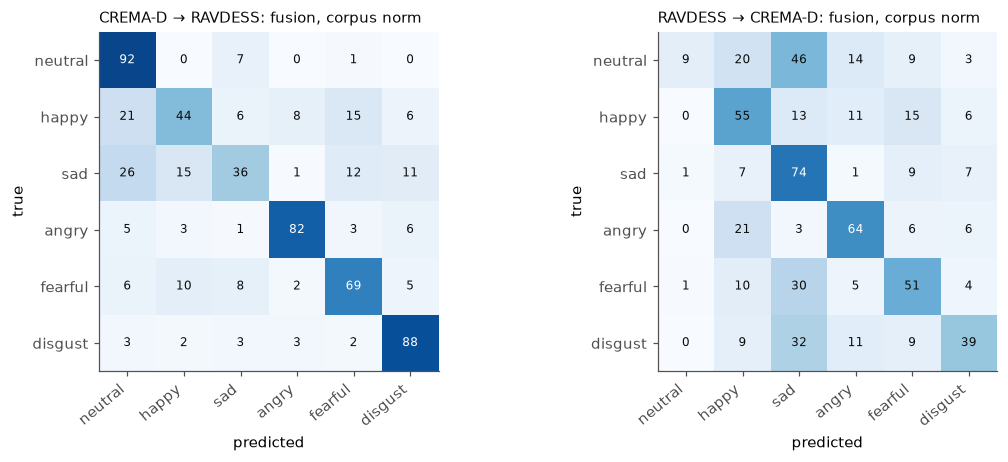

      direction emotion  in_domain_recall  cross_recall   drop
CREMA-D→RAVDESS neutral             0.865         0.917 -0.052
CREMA-D→RAVDESS   happy             0.760         0.438  0.323
CREMA-D→RAVDESS     sad             0.745         0.359  0.385
CREMA-D→RAVDESS   angry             0.896         0.818  0.078
CREMA-D→RAVDESS fearful             0.786         0.688  0.099
CREMA-D→RAVDESS disgust             0.880         0.880  0.000
RAVDESS→CREMA-D neutral             0.864         0.094  0.770
RAVDESS→CREMA-D   happy             0.759         0.550  0.209
RAVDESS→CREMA-D     sad             0.669         0.736 -0.068
RAVDESS→CREMA-D   angry             0.827         0.640  0.186
RAVDESS→CREMA-D fearful             0.644         0.507  0.137
RAVDESS→CREMA-D disgust             0.684         0.391  0.293


In [12]:
best = e2[e2.model == "logreg"].sort_values("cross_uar", ascending=False).groupby("source").head(1)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3))
per_class = []
for ax, r in zip(axes, best.itertuples()):
    t = r.target; y = data[t]["y"]
    pred = np.load(OUT / f"e2_{r.source}_to_{t}_{r.features}_logreg_{r.norm}.npy")
    ind = np.load(P6 / f"e1_{t}_{r.features}_logreg_oof.npy")
    cm = confusion_matrix(y, pred, normalize="true") * 100
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
    for i in range(6):
        for j in range(6):
            ax.text(j, i, f"{cm[i, j]:.0f}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 55 else INK)
    ax.set_xticks(range(6), CLASSES, rotation=40, ha="right"); ax.set_yticks(range(6), CLASSES); ax.grid(False)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"{NAME[r.source]} → {NAME[t]}: {r.features}, {r.norm} norm", loc="left", color=INK, fontsize=10)
    rc = recall_score(y, pred, labels=range(6), average=None); ri = recall_score(y, ind, labels=range(6), average=None)
    per_class += [{"direction": f"{NAME[r.source]}→{NAME[t]}", "emotion": e, "in_domain_recall": round(a, 3),
                   "cross_recall": round(b, 3), "drop": round(a - b, 3)} for e, a, b in zip(CLASSES, ri, rc)]
fig.tight_layout(); fig.savefig(FIG_DIR / "p8_e5_cross_confusion.png", bbox_inches="tight"); plt.show()
per_class = pd.DataFrame(per_class); summary["E5_per_class"] = per_class.to_dict(orient="records")
print(per_class.to_string(index=False))

In [13]:
# Fairness by speaker gender (and CREMA-D age): in-domain (Phase 6 OOF) and cross-corpus, LogReg + WavLM
rows = []
for (s, t) in DIRS:
    d = data[t]; y = d["y"]; meta = d["meta"]
    for fs in ["egemaps", "wavlm"]:
        ind = np.load(P6 / f"e1_{t}_{fs}_logreg_oof.npy")
        crs = np.load(OUT / f"e2_{s}_to_{t}_{fs}_logreg_corpus.npy")
        for gname, mask in [("female", meta["gender"].values == "female"), ("male", meta["gender"].values == "male")]:
            rows.append({"target": NAME[t], "features": fs, "group": gname, "n": int(mask.sum()),
                         "in_domain_uar": round(balanced_accuracy_score(y[mask], ind[mask]), 3),
                         "cross_uar": round(balanced_accuracy_score(y[mask], crs[mask]), 3)})
        if t == "cremad":
            for gname, lo, hi in [("age 20-29", 20, 29), ("age 30-44", 30, 44), ("age 45+", 45, 200)]:
                mask = (meta["age"].values >= lo) & (meta["age"].values <= hi)
                rows.append({"target": NAME[t], "features": fs, "group": gname, "n": int(mask.sum()),
                             "in_domain_uar": round(balanced_accuracy_score(y[mask], ind[mask]), 3),
                             "cross_uar": round(balanced_accuracy_score(y[mask], crs[mask]), 3)})
fair = pd.DataFrame(rows); fair.to_csv(OUT / "e5_groups.csv", index=False)
summary["E5_groups"] = fair.to_dict(orient="records")
fair

,target,features,group,n,in_domain_uar,cross_uar
0,CREMA-D,egemaps,female,3512,0.528,0.366
1,CREMA-D,egemaps,male,3930,0.502,0.347
2,CREMA-D,egemaps,age 20-29,2774,0.530,0.352
3,CREMA-D,egemaps,age 30-44,2624,0.506,0.349
4,CREMA-D,egemaps,age 45+,2044,0.503,0.371
5,CREMA-D,wavlm,female,3512,0.759,0.448
6,CREMA-D,wavlm,male,3930,0.719,0.452
7,CREMA-D,wavlm,age 20-29,2774,0.749,0.455
8,CREMA-D,wavlm,age 30-44,2624,0.736,0.425
9,CREMA-D,wavlm,age 45+,2044,0.726,0.475


In [14]:
# Label quality: CREMA-D clips where listeners agreed with the intended emotion vs not
d = data["cremad"]; y = d["y"]; agree = d["meta"]["voice_agrees"].astype(bool).values
rows = []
for fs in ["egemaps", "wavlm"]:
    ind = np.load(P6 / f"e1_cremad_{fs}_logreg_oof.npy")
    crs = np.load(OUT / f"e2_ravdess_to_cremad_{fs}_logreg_corpus.npy")
    for name, m in [("listeners agreed", agree), ("listeners disagreed", ~agree)]:
        rows.append({"features": fs, "clips": name, "n": int(m.sum()),
                     "in_domain_uar": round(balanced_accuracy_score(y[m], ind[m]), 3),
                     "cross_uar (RAVDESS→CREMA-D)": round(balanced_accuracy_score(y[m], crs[m]), 3)})
agr = pd.DataFrame(rows)
hum = d["meta"].groupby("label")["voice_agrees"].mean().reindex(CLASSES)
mod = pd.Series(recall_score(y, np.load(P6 / "e1_cremad_wavlm_logreg_oof.npy"), labels=range(6), average=None), index=CLASSES)
rho = spearmanr(hum.values, mod.values).statistic
print(f"Per-emotion: human agreement vs model recall (WavLM, in-domain): Spearman {rho:.2f}")
print(pd.DataFrame({"human_agreement": hum.round(3), "model_recall": mod.round(3)}).to_string())
summary["E5_label_quality"] = {"table": agr.to_dict(orient="records"), "human_vs_model_spearman": round(float(rho), 3)}
agr

Per-emotion: human agreement vs model recall (WavLM, in-domain): Spearman 0.60
         human_agreement  model_recall
neutral            0.957         0.861
happy              0.260         0.758
sad                0.164         0.659
angry              0.606         0.815
fearful            0.320         0.648
disgust            0.270         0.687


,features,clips,n,in_domain_uar,cross_uar (RAVDESS→CREMA-D)
0,egemaps,listeners agreed,3099,0.622,0.447
1,egemaps,listeners disagreed,4343,0.445,0.307
2,wavlm,listeners agreed,3099,0.843,0.570
3,wavlm,listeners disagreed,4343,0.672,0.385


In [15]:
(PROJECT_ROOT / "results" / "phase8_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("saved results/phase8_summary.json")

saved results/phase8_summary.json
